# Design a low-MOI screen around a regulon

How many GATA1 targets could a K562 screen recover if each target changed by −0.25 or −0.5 lnFC? Start with the fitted negative-binomial baseline from the [Replogle analysis](replogle.ipynb), plant both effect scenarios, then vary cells per guide. The plotted recovery is conditional on those targets responding at the specified effect size.

As in the Figure 2 benchmark, each simulated cell carries one perfectly effective construct. We resample non-targeting cells’ batch and library-size offsets, draw fresh counts from the fitted model, and run the PerTurbo CLI on each draw. The smaller grid substitutes a real regulon for the benchmark’s randomly assigned targets.

In [1]:
from pathlib import Path
import json
import os
import subprocess
import sys
import tempfile
import time

import anndata as ad
import jax
import matplotlib.pyplot as plt
import mudata as md
import numpy as np
import pandas as pd
from scipy.stats import binomtest

from perturbo.simulation.predictive import sample_predictive_counts

fit_path = Path("runs/replogle/fitted.h5mu")
if not fit_path.is_file():
    raise FileNotFoundError("Run replogle.ipynb first to create runs/replogle/fitted.h5mu.")
md.set_options(pull_on_update=False)
fit = md.read_h5mu(fit_path)
pt = fit.uns["_perturbo"]
rna = fit.mod["rna"]
genes = pd.Index(pt["metadata"]["gene_names"], name="gene")
baseline = pt["control_fit"]
covariates = pt["cell_covariates"]
offsets = pt["size_factors"].reshape(-1, 1)
assert genes.is_unique and rna.obs_names.equals(covariates.index)
assert np.array_equal(genes, rna.var["gene_name"].astype(str))
assert pt["metadata"]["likelihood"] == "negbin"

## Set the design

The source [CollecTRI](https://doi.org/10.1093/nar/gkad841) annotation contains 147 nonself GATA1 targets. Of the 69 present in the original K562 essential screen, 67 averaged at least 0.1 counts per non-targeting cell. The tutorial includes all 67 and uses those 67 as its recovery denominator. The gene panel and targets stay fixed across draws. At each coverage, two synthetic constructs represent alternative GATA1 effect sizes and a third evaluated construct has no effect. A separate set of non-targeting cells anchors the fit. Cells per guide equals cells per construct here.

To keep the grid small, use four well-represented GEM groups from the fitted screen. Each simulated cell inherits one donor’s batch covariates and centered log-depth together. We give the inference CLI that same log-depth, so these estimates assume known offsets.

In [2]:
targets = pd.Index(Path("inputs/gata1_targets.txt").read_text().splitlines(), name="gene")
if not targets.is_unique or not targets.isin(genes).all():
    raise ValueError("This tutorial needs the Replogle analysis gene panel containing all 67 GATA1 targets.")

coverage_grid = [50, 100, 200]     # cells per guide
effects = {"GATA1_weak": -0.25, "GATA1_strong": -0.5}
n_replicates = 4
n_controls = 1024
seed = 2026
q_cutoff = 0.1
if os.getenv("PERTURBO_TUTORIAL_QUICK") == "1":  # CI smoke test
    coverage_grid, n_replicates = [50, 200], 1

batch = rna.obs["gem_group"].astype(str)
control = rna.obs["gene_transcript"].astype(str).str.contains("non-targeting", regex=False)
control_batches = batch[control].value_counts().head(4).index
donor_pool = np.flatnonzero(control & batch.isin(control_batches))
target_columns = genes.get_indexer(targets)
scenarios = pd.DataFrame([
    {"element": f"{condition}_{coverage}", "condition": condition,
     "cells_per_guide": coverage, "effect": effect}
    for coverage in coverage_grid
    for condition, effect in {**effects, "null_construct": 0.0}.items()
])
elements = [*scenarios.element, "non-targeting"]
beta = np.zeros((len(elements), len(genes)), dtype=np.float32)
beta[:-1, target_columns] = scenarios.effect.to_numpy()[:, None]
sites = {name: baseline[name] for name in ("beta_0", "theta", "covariate_coef")}
sites["beta"] = beta
print(f"{len(targets)} targets among {len(genes)} tested genes; {len(donor_pool):,} eligible donor cells.")
scenarios

67 targets among 256 tested genes; 130 eligible donor cells.


,element,condition,cells_per_guide,effect
0,GATA1_weak_50,GATA1_weak,50,-0.25
1,GATA1_strong_50,GATA1_strong,50,-0.50
2,null_construct_50,null_construct,50,0.00
3,GATA1_weak_100,GATA1_weak,100,-0.25
4,GATA1_strong_100,GATA1_strong,100,-0.50
5,null_construct_100,null_construct,100,0.00
6,GATA1_weak_200,GATA1_weak,200,-0.25
7,GATA1_strong_200,GATA1_strong,200,-0.50
8,null_construct_200,null_construct,200,0.00


## Generate one screen

Each construct label identifies one coverage and effect scenario. We sample exactly that many assigned cells. Combining scenarios into one screen lets them share one control population and baseline fit, as in a pooled low-MOI experiment. Each replicate gets independent donor draws and independently simulated counts. Inference corrects for multiple testing separately within each construct.

In [3]:
def simulate_screen(replicate):
    streams = np.random.SeedSequence([seed, replicate]).spawn(2)
    rng = np.random.default_rng(streams[0])
    key = jax.random.PRNGKey(streams[1].generate_state(1)[0])
    assignments = np.repeat(np.arange(len(elements)), [*scenarios.cells_per_guide, n_controls])
    assignments = rng.permutation(assignments).astype(np.int32)
    donors = rng.choice(donor_pool, size=len(assignments), replace=True)
    counts, simulated_offsets = sample_predictive_counts(
        sites, assignments, key,
        size_factors=offsets[donors], covariates=covariates.iloc[donors].to_numpy(),
        likelihood="nb",
    )
    np.testing.assert_array_equal(simulated_offsets, offsets[donors])
    obs = pd.DataFrame({
        "construct": np.array(elements)[assignments],
        "gem_group": batch.iloc[donors].to_numpy(),
        "log_sf": simulated_offsets.ravel(),
    }, index=[f"sim_{i}" for i in range(len(donors))])
    return ad.AnnData(counts, obs=obs, var=pd.DataFrame(index=genes))

## Run the grid

Use the control-anchored test from the low-MOI analysis. Each draw gets its own baseline fit and p-values. Stage two can be skipped because the endpoint is a detection call. For each construct, `q_element` applies BH across the finite p-values for the **whole tutorial RNA panel**; only afterward do we summarize GATA1 targets. The family size will change if you change the panel.

The loop retains the simulated input, fitted output and CLI log for each draw. Each execution starts a new directory so you can compare designs.

In [4]:
parent = Path("runs/replogle-power")
parent.mkdir(parents=True, exist_ok=True)
run = Path(tempfile.mkdtemp(prefix="grid-", dir=parent))
started = time.perf_counter()
parts = []
for replicate in range(n_replicates):
    draw = run / f"rep{replicate:02d}"
    draw.mkdir()
    screen = simulate_screen(replicate)
    screen.write_h5ad(draw / "screen.h5ad", compression="gzip")
    command = [
        sys.executable, "-m", "perturbo.cli", "--input", str(draw / "screen.h5ad"),
        "--out-dir", str(draw / "fit"), "--device", "cpu", "--no-progress-bar",
        "--perturbation-key", "construct", "--control-substring", "non-targeting",
        "--batch-covariate", "gem_group", "--size-factor-key", "log_sf",
        "--size-factor-mode", "observed", "--likelihood", "negbin",
        "--crt-only", "--crt-pool", "control-anchored", "--crt-mechanism", "propensity",
        "--crt-tail-families", "saddlepoint", "--crt-saddlepoint-only",
        "--crt-polish-baseline", "--num-steps", "1000", "--step-size", "0.01",
        "--crt-gene-chunk-size", "32", "--crt-max-gather-gib", "1",
    ]
    (draw / "command.json").write_text(json.dumps(command, indent=2))
    with (draw / "cli.log").open("w") as log:
        status = subprocess.run(command, stdout=log, stderr=subprocess.STDOUT)
    if status.returncode:
        raise RuntimeError(f"PerTurbo failed. See {draw / 'cli.log'}.")
    result = md.read_h5mu(draw / "fit/fitted.h5mu").uns["_perturbo"]["effects"]
    result = result.loc[result.element.isin(elements[:-1]), ["element", "gene", "p_value", "q_element"]].copy()
    assert not result.duplicated(["element", "gene"]).any()
    assert set(result.element) == set(elements[:-1]) and set(result.gene) == set(genes)
    assert len(result) == (len(elements) - 1) * len(genes)
    parts.append(result.merge(scenarios, on="element", validate="many_to_one").assign(replicate=replicate))
    print(f"Completed replicate {replicate + 1}/{n_replicates}.", flush=True)

pairs = pd.concat(parts, ignore_index=True)
pairs["planted"] = pairs.condition.isin(effects) & pairs.gene.isin(targets)
pairs["lnfc"] = pairs.effect.where(pairs.planted, 0)
pairs["supported"] = pairs.p_value.notna()
pairs["detected"] = pairs.q_element.lt(q_cutoff)
pairs.to_parquet(run / "pair_calls.parquet", index=False)
print(f"Elapsed: {(time.perf_counter() - started) / 60:.1f} min. Results: {run}")

Completed replicate 1/4.


Completed replicate 2/4.


Completed replicate 3/4.


Completed replicate 4/4.


Elapsed: 1.6 min. Results: runs/replogle-power/grid-tg86r7uv


## Coverage and target recovery

A point in the left panel is one screen’s detected fraction across all 67 planted targets, including any targets with unsupported tests in the denominator. The lines are replicate means. The heatmap gives the per-gene detection frequency for the stronger effect. Genes are ordered by their observed mean expression in the eligible control donors. With four replicates, individual frequencies have 25-percentage-point resolution. Increase `n_replicates` for a quantitative design recommendation.

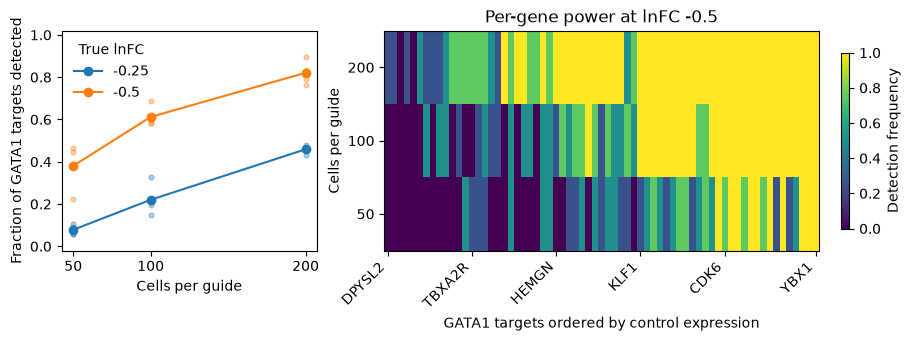

In [5]:
keys = ["condition", "cells_per_guide", "replicate"]
recovery = pairs.loc[pairs.planted].groupby(keys, observed=True).detected.mean().rename("recovery").reset_index()
by_gene = pairs.loc[pairs.planted].groupby(
    ["condition", "cells_per_guide", "gene"], observed=True
).detected.agg(["sum", "size", "mean"]).reset_index()
# A binomial interval describes uncertainty across independent draws for a single pair.
intervals = [binomtest(k, n).proportion_ci(method="wilson") for k, n in zip(by_gene["sum"], by_gene["size"])]
by_gene["lower_95"] = [ci.low for ci in intervals]
by_gene["upper_95"] = [ci.high for ci in intervals]
by_gene.to_csv(run / "target_power.csv", index=False)

expression = np.asarray(rna.X[donor_pool][:, target_columns].mean(axis=0)).ravel()
ordered = targets[np.argsort(expression, kind="stable")]
strong = min(effects, key=effects.get)
matrix = by_gene.loc[by_gene.condition.eq(strong)].pivot(
    index="cells_per_guide", columns="gene", values="mean"
).loc[coverage_grid, ordered]

fig, (curve, heat) = plt.subplots(1, 2, figsize=(9, 3.3), width_ratios=[1, 1.7], layout="constrained")
for element, effect in effects.items():
    rows = recovery.loc[recovery.condition.eq(element)]
    mean = rows.groupby("cells_per_guide").recovery.mean()
    line, = curve.plot(mean.index, mean, "o-", label=f"{effect:g}")
    curve.scatter(rows.cells_per_guide, rows.recovery, color=line.get_color(), alpha=0.35, s=12)
curve.set(xlabel="Cells per guide", ylabel="Fraction of GATA1 targets detected",
          xticks=coverage_grid, ylim=(-0.02, 1.02))
curve.legend(title="True lnFC", frameon=False)

image = heat.imshow(matrix, cmap="viridis", vmin=0, vmax=1, aspect="auto", interpolation="nearest", origin="lower")
heat.set(yticks=range(len(coverage_grid)), yticklabels=coverage_grid, ylabel="Cells per guide",
         xlabel="GATA1 targets ordered by control expression", title=f"Per-gene power at lnFC {effects[strong]:g}")
ticks = np.linspace(0, len(ordered) - 1, 6, dtype=int)
heat.set_xticks(ticks, ordered[ticks], rotation=45, ha="right")
fig.colorbar(image, ax=heat, label="Detection frequency", shrink=0.8)
fig.savefig(run / "regulon-power.pdf", bbox_inches="tight")
plt.show()

The null construct provides an empirical check on false calls. The table gives counts per screen before averaging over replicates. Unsupported tests stay visible separately. A larger number of recovered targets here indicates greater sensitivity under the planted effect distribution. Estimating which links the real perturbation activates additionally requires observed differential expression.

In [6]:
summary = pairs.groupby(keys, observed=True).agg(
    tested_pairs=("gene", "size"), unsupported=("supported", lambda x: (~x).sum()),
    calls=("detected", "sum"),
).reset_index()
summary.groupby(["condition", "cells_per_guide"], observed=True)[["tested_pairs", "unsupported", "calls"]].mean()

tested_pairs  unsupported  calls
condition      cells_per_guide                                  
GATA1_strong   50                      256.0          0.0  27.50
               100                     256.0          0.0  43.00
               200                     256.0          0.0  59.00
GATA1_weak     50                      256.0          0.0   5.50
               100                     256.0          0.0  15.50
               200                     256.0          0.0  33.75
null_construct 50                      256.0          0.0   0.00
               100                     256.0          0.0   0.50
               200                     256.0          0.0   0.00